<a href="https://colab.research.google.com/github/aurelianmoge/CE-4110-UVa-personal-work/blob/main/Homework5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Homework 5

Adaptation of Question 5.1 from Loucks and van Beek. A reservoir serves multiple purposes. It is a recreation site for swimmers, wind surfers and boaters; a flood storage reservoir; and an irrigation supply structure. Each season, there is a required minimum release for irrigation to meet water rights downstream. Reservoir releases in excess of the irrigation requirement flow to a wetland downstream. The wetland also receives return flows from irrigation, equal to 30\% of the water diverted for irrigation. These return flows are highly saline, which can damage the ecosystem. Different target water allocations are favorable for each of these objectives. Based on mean inflows across 4 seasons, your task is to determine how much water should be released from the reservoir in each season to minimize the sum of percent deviation across all targets given the following parameters and targets:

* Reservoir storage capacity, $K$: 30 million m$^3$ (mcm)
* Maximum reservoir release, $Rmax$: 50 mcm
* Reservoir average seasonal inflows, $Qin$: 10, 40, 30, 20 mcm
* Minimum releases for irrigation each season, $Qirr$: 5, 20, 10, 5 mcm
* Salinity concentration of reservoir water, $Cres$: 1 part per trillion (ppt)
* Salinity concentration of irrigation return flow water, $Cirr$: 20 ppt
* Target salinity concentration in the wetland, $Cwet\_maxTarget$: 5 ppt
* Target minimum flow in the wetland each season, $Qwet\_minTarget$: 10, 20, 15, 15 mcm
* Target reservoir storages each period, $S$: 20, 5, 20, 20 mcm

## Part a

Draw a mass flow diagram of the water and salt movement into and through the system in a given season $t$. (5 pts)

See the attached png above!

## Part b

Write a Python function $\texttt{calcCostNLP}$ similar to the one in \texttt${DPexample.ipynb}$ that takes as input a vector $x$ of length 8, where the first 4 values are release decisions each season and the last 4 values are storage levels each season. Have the function return the sum of percent deviation from all targets, where percent deviations above or below storage targets are penalized, but only deviations below minimum wetland flow targets and above wetland salinity concentrations are penalized. Note, the wetland salinity concentration can be computed based on the mass balance: salinity $\times$ flow = mass of salt, and mass of salt in wetland = mass of salt from reservoir water + mass of salt from irrigation return flows. (10 pts)

$\color{red}{\text{Import libraries and define parameters. Code below is complete.}}$

In [65]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import pandas as pd

# define model parameters
# reservoir parameters
K = 30
maxR = 50
Qin = np.array([10,40,30,20])
S_target = np.array([20, 5, 20, 20])

# irrigation parameters
Qirr = np.array([5,20,10,5])
Qirr_RF =  0.3

# salinity parameters
Cres = 1
Cirr = 20
Cwet_maxTarget = 5

# wetland parameters
Qwet_minTarget = np.array([10,20,15,15])

$\color{red}{\text{Below, write $\texttt{calcCostNLP}$ function.}}$

In [66]:
# optimize with scipy.optimize.minimize
def calcCostNLP(x):
  # convert decision variables to state variables
  R = x[0:4]
  S = x[4::]

  # write code to compute total deviation

  # Calculate flows reaching the wetland
  # (bypass >= 0 is guaranteed by the lower bound R >= Qirr in the optimization)
  bypass = R - Qirr
  return_flow = Qirr_RF * Qirr
  Qwet = bypass + return_flow

  # Wetland concentration = total salt mass / total flow
  Cwet = (Cres * bypass + Cirr * return_flow) / Qwet

  # Penalize storage deviations above and below targets
  S_deviation = np.sum(
      100 * np.abs(S - S_target) / S_target
  )

  # Penalize only wetland flow below minimum targets
  Qwet_deviation = np.sum(
      100 * np.maximum(Qwet_minTarget - Qwet, 0) / Qwet_minTarget
  )

  # Penalize only salinity above the maximum target
  Cwet_deviation = np.sum(
      100 * np.maximum(Cwet - Cwet_maxTarget, 0) / Cwet_maxTarget
  )

  total_deviation = S_deviation + Qwet_deviation + Cwet_deviation

  return total_deviation

## Part c

Using $\texttt{BFGS}$ in $\texttt{scipy.optimize.minimize}$ and your $\texttt{calcCostNLP}$ function, find the optimal releases each season to minimize the sum of percent deviations. Be sure to constrain the optimization to preserve reservoir mass balance constraints. As an initial estimate for the optimizer, use the reservoir inflows each season as the release estimates for those seasons, and the storage targets each season as the storage level estimates for those seasons. (10 pts)

$\color{red}{\text{Complete code below.}}$

In [67]:
# define mass balance constraints
constraints = ({'type': 'eq', 'fun': lambda x: x[5] - x[4] - Qin[0] + x[0]},
               # mass balance t=0->1
               {'type': 'eq', 'fun': lambda x: x[6] - x[5] - Qin[1] + x[1]},
               # mass balance t=1->2
               {'type': 'eq', 'fun': lambda x: x[7] - x[6] - Qin[2] + x[2]},
               # mass balance t=2->3
               {'type': 'eq', 'fun': lambda x: x[4] - x[7] - Qin[3] + x[3]})
# mass balance t=3->0, t4=t0 (cyclic)

# initialize guesses at R = Qin and S = S_target
x0 = np.concatenate((Qin, S_target), 0)

# R is between Qirr and 50, S is positive and can't exceed capacity K
bounds = np.concatenate(([[Qirr[t], maxR] for t in range(4)],
 [[0, K]]*4), 0).tolist()

# minimize calcCostNLP
result = minimize(calcCostNLP, x0, bounds=bounds, constraints=constraints)

# print optimal releases
print("Optimal Releases: ", result.x[0:4])
print("Optimal Storages: ", result.x[4::])
print("Total percent deviation: ", result.fun)

Optimal Releases:  [24.99999475 33.999994   21.99999977 19.00001149]
Optimal Storages:  [19.99999526  5.00000051 11.00000651 19.00000674]
Total percent deviation:  84.00003338504935


## Part d

Now modify the two functions $\texttt{calcCostDP}$ and $\texttt{findBestR}$ from [08_DPexample2.ipynb](https://colab.research.google.com/github/EnvSystemsUVA/CodingExamples/blob/main/08_DPexample2.ipynb) to optimize operations for this problem with DP. $\texttt{calcCostDP}$ will loop through all discretized storage levels at time $t$ to determine the optimal release that minimizes the present + future cost (total percent deviations from all targets). Within each loop, it will do that by calling $\texttt{findBestR}$ with $\texttt{scipy.optimize.minimize}$. Constrain this optimization so that the reservoir capacity is not exceeded and the storage is not negative. Use the minimum irrigation flow each season as the initial estimate for the optimization. (20 pts - 10 pts per function)

$\texttt{calcCostDP}$ should take as input the following:

* $S$: 1-D array of discrete storage values representing the states
* $Q$: Scalar of the inflow to the reservoir at this stage
* $Qirr$: Scalar of the irrigation flow requirement at this stage
* $S\_target$: Scalar of the storage target in the next stage
* $Cwet\_maxTarget$: Scalar of the maximum wetland salinity target
* $Qwet\_minTarget$: Scalar of the minimum wetland flow target
* $bounds$: 1-D array of lower and upper bounds on release in this stage
* $FutureCost$: 1-D array of the future costs associated with each stage

And output:

* $Rbest$: 1-D array of optimal releases as a function of $S$
* $Cbest$: 1-D array of present + future costs associated with each value of $S$

$\texttt{findBestR}$ should take as input the following:

* $R$: scalar representing the release we are trying to find the optimal value for
* $sCurrent$: scalar representing the storage level at which we are trying to find the optimal release
* $States$: 2-D array of storage states for interpolating the future value
* $S\_target$: Same as above
* $Cwet\_maxTarget$: Same as above
* $Qwet\_minTarget$: Same as above
* $Q$: Same as above
* $Qirr$: Same as above
* $FutureCost$: Same as above

And output:

* $TotalCost$: the present + future cost associated with the release $R$ at this storage $sCurrent$ given inflow $Q$

$\color{red}{\text{Complete these functions in the code chunk below.}}$

In [68]:
def findBestR(R, sCurrent, States, S_target, Cwet_maxTarget,
              Qwet_minTarget, Q, Qirr, FutureCost):
  # get first element of vector of length 1 of decision variables
  R = R[0]

  # find what state that release would result in
  sNext = sCurrent + Q - R

  # Calculate flows reaching the wetland
  # (bypass >= 0 is guaranteed by the lower bound R >= Qirr in the optimization)
  bypass = max(R - Qirr, 0)
  return_flow = Qirr_RF * Qirr
  Qwet = bypass + return_flow

  # Wetland concentration = total salt mass / total flow
  Cwet = (Cres * bypass + Cirr * return_flow) / Qwet

  # percent deviation from the storage target (above or below)
  S_deviation = abs(sNext - S_target) / S_target * 100

  # wetland flow: only deviations BELOW the minimum target are penalized
  Qwet_deviation = max(Qwet_minTarget - Qwet, 0) / Qwet_minTarget * 100

  # wetland salinity: only deviations ABOVE the maximum target are penalized
  Cwet_deviation = max(Cwet - Cwet_maxTarget, 0) / Cwet_maxTarget * 100

  # calculate the future cost at that state through interpolation
  # and add to the current cost
  CurrentCost = S_deviation + Qwet_deviation + Cwet_deviation
  TotalCost = CurrentCost + np.interp(sNext, States, FutureCost)

  return TotalCost

def calcCostDP(S, Q, Qirr, S_target, Cwet_maxTarget,
               Qwet_minTarget, bounds, FutureCost):
  '''
  Function to calculate the optimal release (Rbest) from each storage state (S)
  and associated present and future cost (Cbest), defined as the total percent
  deviation from the storage, wetland flow,
  and wetland salinity targets for that stage.

  Inputs:
    S: array of discrete storage values representing the states
    Q: inflow received at this stage
    Qirr: minimum irrigation release requirement at this stage
    S_target: target storage for next stage
    Cwet_maxTarget: target maximum wetland salinity concentration
    Qwet_minTarget: target minimum wetland flow at this stage
    bounds: lower and upper bounds on possible releases at this stage
    FutureCost: array of future costs at each state that will be added to
    cost of the optimal state transition at this stage to compute present
    + future cost

  Outputs:
    Rbest: array of optimal releases from each state in S
    Cbest: array of present + future costs associated with each state S
  '''

  # initialize current cost at infinity and releases at 0
  Cbest = np.empty([len(S)])+np.inf
  Rbest = np.zeros([len(S)])
  for i, s in enumerate(S): # storage at stage t
    # find optimal release from this state
    constraints = ({'type': 'ineq', 'fun': lambda x: K - (s + Q - x[0])},
                   # capacity - Snext >= 0
                   {'type': 'ineq', 'fun': lambda x: s + Q - x[0]})
    # Snext >= 0
    result = minimize(findBestR, x0=Qirr, bounds=[[bounds[0], bounds[1]]],
                      constraints=constraints,
                      args=(s, S, S_target, Cwet_maxTarget, Qwet_minTarget,
                            Q, Qirr, FutureCost))
    Rbest[i] = result.x[0]
    Cbest[i] = result.fun

  return Rbest, Cbest

$\color{red}{\text{Define DP parameters and variables that will store costs and release policies. The code below is complete.}}$

In [69]:
# get indices of stages
nStages = len(Qin)
forward_indices = np.arange(nStages)
backward_indices = forward_indices[::-1]
backward_indices = np.insert(backward_indices,0,0)

# discretize states
states = np.arange(0,31,5)
nStates = len(states)

# bounds on decision variables (releases)
bounds = bounds[0:4]

# initialize matrices with costs of each state at each stage
# and optimal releases to make from each state at each stage
costs = np.empty([nStates,nStages])
release_policy = np.empty([nStates,nStages])

# initialize FutureCost at 0 for all states; will update as we move backwards
FutureCost = np.zeros([nStates])

## Part e

Now run backward-moving DP with the code chunk below, which uses the functions you wrote above to solve for the optimal release from each storage level. Have it stop when the average difference in the release decisions at each state change by less than $0.1\%$ in a given stage from one cycle through all seasons to the next. (5 pts)

$\color{red}{\text{Complete the code below to find the optimal release policy with DP, convert it to a data frame, and print it.}}$

In [70]:
# write backward-moving DP
loop = True
tolerance = 0.1 # average % difference in optimal releases from one cycle
#to the next at which to stop looping
avgPctDiff = np.inf
cycle = 0 # number of times cycling through all seasons
while loop:
    count = 0
    cycle += 1
    for index in backward_indices[0:-1]:
        # find optimal release and value of each state in this stage
        # states (storage targets) are for next period (index)
        # while inflows, irrigation
        # releases and wetland flow targets are for this period (index-1)
        R, FutureCost = calcCostDP(states, Qin[index-1], Qirr[index-1],
                                   S_target[index],
                                   Cwet_maxTarget, Qwet_minTarget[index-1],
                                   bounds[index-1], FutureCost)

        # find average % difference in optimal releases at this stage
        # compared to the last loop
        if cycle > 1:
            avgPctDiff = np.mean(np.abs(R - release_policy[:,index-1])*100
                                 / release_policy[:,index-1])
            print(avgPctDiff)
            if avgPctDiff < tolerance:
                count += 1

        # update best releases and value of each state
        costs[:,index] = FutureCost
        release_policy[:,index-1] = R

    # stop loop if average % difference is below tolerance
    # at all stages in this cycle
    if count == len(backward_indices[0:-1]):
        break

# convert release policy to a dataframe and print it
release_policy_df = pd.DataFrame(release_policy,
                                 columns=["Season 1","Season 2","Season 3",
                                          "Season 4"],index=states)
release_policy_df.index.rename("Storage",inplace=True)
release_policy_df

8.783784361775073
1.9301721975482764e-06
0.00014194516973261984
2.1971141276644736e-07
1.015467032556058e-06
1.9309860015900242e-08
6.016180331440116e-06
1.9633566739705625e-06


,Season 1,Season 2,Season 3,Season 4
Storage,,,,
0,10.000000,30.028921,21.249998,10.625000
5,10.000002,34.000000,21.250000,14.999999
10,15.000000,34.999996,21.250001,18.499999
15,20.000000,35.354193,25.000000,18.500000
20,25.000000,40.000003,30.000000,20.000000
25,30.000000,45.000000,35.000000,25.000000
30,34.999999,50.000000,40.000000,30.000000


## Part f

Now consider that there is actually uncertainty in the reservoir inflows each season. The probability mass function (PMF) of discrete inflows observed each season are the following:
        \begin{align}
            \text{Season 1:} &\quad p(Q=5) = 0.25, \quad p(Q=10) = 0.75 \\
            \text{Season 2:} &\quad p(Q=40) = 0.75 \quad p(Q=50) = 0.25 \\
            \text{Season 3:} &\quad p(Q=25) = 0.25, \quad p(Q=30) = 0.50, \quad p(Q=35) = 0.25 \\
            \text{Season 4:} &\quad p(Q=10) = 0.25, \quad p(Q=20) = 0.50 \quad p(Q=25) = 0.25
        \end{align}
Simulate 50 years of operations in which the release each season is always that found to be optimal by the NLP in part (c). Repeat this using the operating policy found to be optimal using DP in part (d). In both cases, start the simulation at the target reservoir storage for the first season. If there is insufficient water to meet the release prescribed by the policy, only release as much water as is available. Likewise, if the prescribed release would result in exceeding the reservoir capacity, release as much as needed to prevent that (this may not meet the irrigation requirement, or may exceed 50, but that's okay for the purpose of this simulation). Record the percent deviations from storage, salinity, and wetland flow targets each year. Hint: modify the $\texttt{Solution}$ class from $\texttt{DPexample.ipynb}$ to calculate $simQwet$, $simCwet$, $Qwet\_costs$, and $Cwet\_costs$, and modify the existing equations for $S\_cost$ and $Total\_costs$. (10 pts)

$\color{red}{\text{Complete the code below. Write the functions $\texttt{getSimStates}$ and $\texttt{getSimCosts}$. Populate $inflows$ and $probs$ for the PMF of flows each season.}}$  
$\color{red}{\text{Finally, complete the loops below $seed=0$ to simulate $nYears$ of $nSeasons$ of operations with the DP and NLP policies.}}$

In [71]:
# initialize storages and releases for simulation of 50 years of 4 seasons with NLP and DP policies
nYears = 50
nSeasons = 4

class Solution():
  # initialize Solution class with certain attributes for DP vs. NLP solution
  def __init__(self):
    self.simS = np.zeros([nYears,nSeasons])
    self.simR = np.zeros([nYears,nSeasons])
    self.simQwet = np.zeros([nYears,nSeasons])
    self.simCwet = np.zeros([nYears,nSeasons])
    self.S_costs = np.zeros([nYears])
    self.Qwet_costs = np.zeros([nYears])
    self.Cwet_costs = np.zeros([nYears])
    self.Total_costs = np.zeros([nYears])
    self.prescribedR = None

  # method of Solution class to calculate simulated R and S
  def getSimStates(self, Q, year, season):
    # adjust prescribed release if not physically possible
    # R = min(prescribedR, simS + Q) prevents it from releasing more water
    # than is available
    # max(simS + Q - K, R) prevents storage capacity from being exceeded
    self.simR[year,season] = max(self.simS[year,season] + Q - K,
                                 min(self.prescribedR,
                                     self.simS[year,season] + Q))

    # calculate new storage
    if season != (nSeasons-1): # storage in next season of same year
      self.simS[year,season+1] = self.simS[year,season] + Q - self.simR[year,season]
    elif year != (nYears-1): # storage in season 1 of next year
      self.simS[year+1,0] = self.simS[year,season] + Q - self.simR[year,season]

    # Calculate flows reaching the wetland
    diverted = min(self.simR[year,season], Qirr[season])
    bypass = self.simR[year,season] - diverted
    return_flow = Qirr_RF * diverted
    self.simQwet[year,season] = bypass + return_flow
    self.simCwet[year,season] = (Cres * bypass + Cirr * return_flow) / self.simQwet[year,season]

  # method of Solution class to calculate cost (total deviation from targets)
  def getSimCosts(self, year):
    # storage: deviations above AND below target are penalized
    self.S_costs[year] = np.sum(np.abs(self.simS[year,:] - S_target) /
                                S_target * 100)
    # wetland flow: only deviations BELOW the minimum target are penalized
    self.Qwet_costs[year] = np.sum(np.maximum(Qwet_minTarget -
                                              self.simQwet[year,:], 0) \
                                   / Qwet_minTarget * 100)
    # wetland salinity: only deviations ABOVE the maximum target are penalized
    self.Cwet_costs[year] = np.sum(np.maximum(self.simCwet[year,:] -
                                              Cwet_maxTarget, 0) \
                                    / Cwet_maxTarget * 100)
    self.Total_costs[year] = self.S_costs[year] + self.Qwet_costs[year] + self.Cwet_costs[year]

# PMF of inflows each season
inflows = np.array([[5, 10, 10],     # season 1
                    [40, 50, 50],    # season 2
                    [25, 30, 35],    # season 3
                    [10, 20, 25]])   # season 4
probs = np.array([[0.25, 0.75, 0.0],
                  [0.75, 0.25, 0.0],
                  [0.25, 0.50, 0.25],
                  [0.25, 0.50, 0.25]])

# create objects of Solution class for NLP and DP solutions
DP = Solution()
NLP = Solution()

# start at target storage
DP.simS[0,0] = S_target[0]
NLP.simS[0,0] = S_target[0]

# simulate operations over 50 years of 3 seasons
seed = 0
for year in range(nYears):
  for season in range(nSeasons):
    # generate inflow
    seed += 1
    np.random.seed(seed)
    Q = np.random.choice(inflows[season,:], 1, p=probs[season,:])[0]

    # find DP release from policy (interpolating between discretized states);
    # NLP release is fixed each season
    DP.prescribedR = np.interp(DP.simS[year,season], states,
                               release_policy[:,season])
    NLP.prescribedR = result.x[season]

    # find actual release (what is physically possible) and
    # calculate storage from mass balance
    DP.getSimStates(Q, year, season)
    NLP.getSimStates(Q, year, season)

  # calculate total cost (percent deviations from targets) in simulated year
  DP.getSimCosts(year)
  NLP.getSimCosts(year)

# compare average annual percent deviations of each policy
AvgCostTable = pd.DataFrame({'Storage': [np.mean(NLP.S_costs),
                                         np.mean(DP.S_costs)],
                             'Wetland Flow': [np.mean(NLP.Qwet_costs),
                                              np.mean(DP.Qwet_costs)],
                             'Wetland Salinity': [np.mean(NLP.Cwet_costs),
                                                  np.mean(DP.Cwet_costs)],
                             'Total': [np.mean(NLP.Total_costs),
                                       np.mean(DP.Total_costs)]},
                            index=["NLP", "DP"])
AvgCostTable.index.rename("Policy", inplace=True)
AvgCostTable

,Storage,Wetland Flow,Wetland Salinity,Total
Policy,,,,
NLP,172.099996,2.100032,34.461574,208.661603
DP,94.767269,7.723970,40.338162,142.829400


## Part g

Based on your simulation from part (e), make a 2x2 panel figure of the empirical cumulative distribution function of total percent deviations each year from the storage, salinity, and wetland flow targets, as well as the sum across all three. Do this for the policies from parts (c) and (d) using a different color for each. (8 pts)

$\color{red}{\text{Use the code chunk below to make your plot.}}$

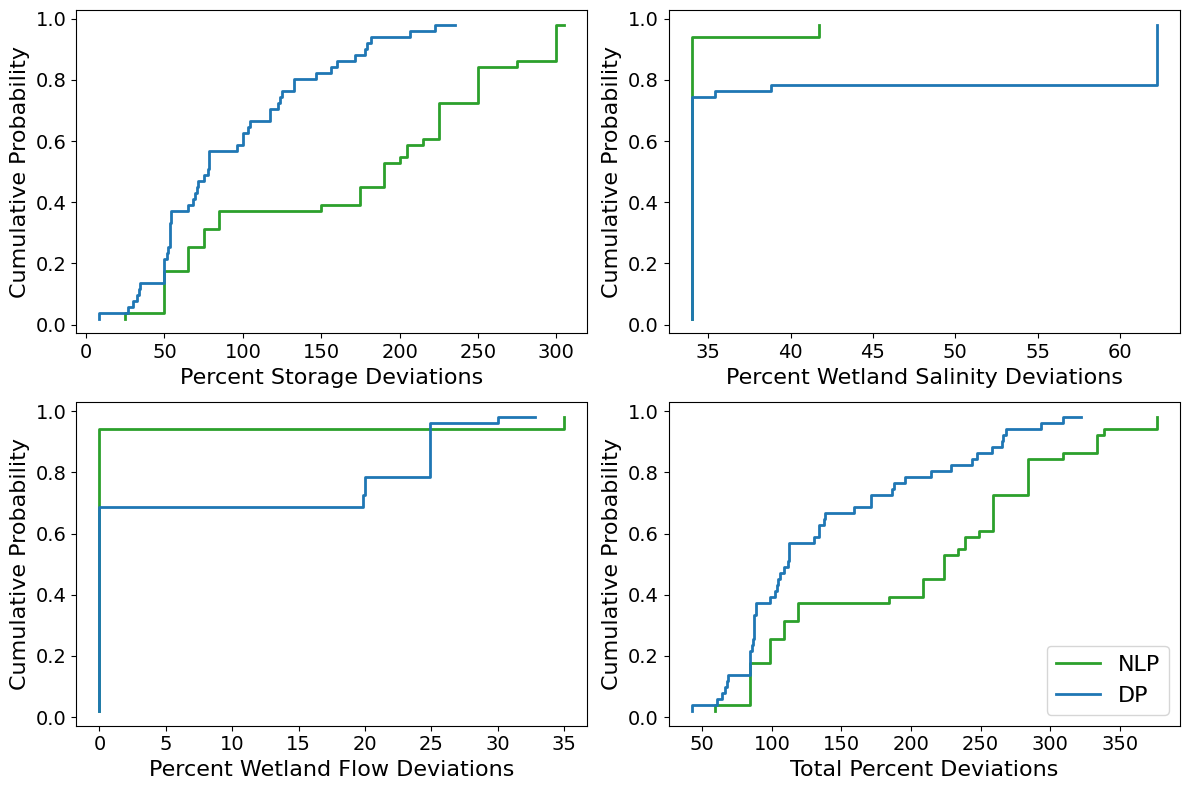

In [72]:
# cumulative probabilities
p = np.arange(1,nYears+1,1) / (nYears+1)

# plot ECDF of storage, salinity, wetland flow and
# total percent deviations for each policy
fig = plt.figure(figsize=[12,8])

# make list of things to loop through for each plot
DP_costs = [DP.S_costs, DP.Cwet_costs, DP.Qwet_costs, DP.Total_costs]
NLP_costs = [NLP.S_costs, NLP.Cwet_costs, NLP.Qwet_costs, NLP.Total_costs]
xlabels = ["Percent Storage Deviations", "Percent Wetland Salinity Deviations",
           "Percent Wetland Flow Deviations", "Total Percent Deviations"]

for i in range(len(DP_costs)):
  ax = fig.add_subplot(2,2,i+1)
  # step-function of sorted percent deviations from target for each algorithm
  l1, = ax.step(np.sort(NLP_costs[i]),p,color="tab:green",linewidth=2)
  l2, = ax.step(np.sort(DP_costs[i]),p,color="tab:blue",linewidth=2)
  ax.set_xlabel(xlabels[i], fontsize=16)
  ax.set_ylabel("Cumulative Probability", fontsize=16)
  ax.tick_params(axis="both",labelsize=14)

ax.legend([l1, l2],["NLP","DP"],fontsize=16,loc="lower right")
fig.tight_layout()
fig.show()

$\color{red}{\text{Discuss the differences you see in performance between the operating policies found using NLP vs. DP and why. (2 pts)}}$

The DP operating policy performs better than the NLP policy overall, especially for the storage and total deviations: the DP ECDF performs better than the NLP ECDF.

One might explain that difference by feedback processes. The NLP solution is a fixed vector of releases that is only optimal for the mean inflows. The DP policy instead prescribes a release as a function of the current storage.

The wetland flow and salinity deviations are more similar between the two policies. However, this comes at the cost of large storage deviations, so the DP policy achieves a lower total percent deviation. Even though neither model accounted for inflow uncertainty in the optimization, the state-dependent DP rule is robust to it, while the open-loop NLP rule is not.

**My use of AI**

For this assignment, I used Mistral AI (the French lab that modestly tries to compete with the US ones) for the coding part only.

My typical use of the tool consisted in ask to improve and to simplify the muddled functions I first wrote. I also asked him to help me adapt the functions in the coding example to the problem as I understood it, or to turn my code rows into clean loops.
A few parts, like in the two last cells, have been largely improved through the auto completion options of this tool.